# Getting final dataset from HDFS

In [6]:
import os
import sys
import glob

os.environ["SPARK_HOME"] = "/usr/local/spark"
os.environ["PYSPARK_PYTHON"] = sys.executable

sys.path.insert(0, "/usr/local/spark/python")
sys.path.insert(
    0,
    glob.glob("/usr/local/spark/python/lib/py4j-*.zip")[0]
)

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("CA1_NeuralNetwork") \
    .getOrCreate()

print("Spark version:", spark.version)

Spark version: 4.1.2


In [7]:
# Load final labelled dataset

DATA_PATH = "hdfs://127.0.0.1:9000/ca1/processed/comments_labeled"

dataset = spark.read.parquet(DATA_PATH)

print("Rows:", dataset.count())
print("Columns:", len(dataset.columns))

dataset.printSchema()
dataset.show(5, truncate=80)

Rows: 108524
Columns: 11
root
 |-- comment_id: string (nullable = true)
 |-- video_id: string (nullable = true)
 |-- comment_text: string (nullable = true)
 |-- video_title: string (nullable = true)
 |-- video_description: string (nullable = true)
 |-- video_tags: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- video_age_at_comment: double (nullable = true)
 |-- comment_hour: integer (nullable = true)
 |-- comment_weekday: integer (nullable = true)
 |-- label: integer (nullable = true)
 |-- video_category: integer (nullable = true)

+--------------------------+-----------+----------------------------------------------+------------------------------------------------------------+--------------------------------------------------------------------------------+--------------------------------------------------------------------------------+--------------------+------------+---------------+-----+--------------+
|                comment_id|   video_id|          

# EDA

In [1]:
%pip install pandas seaborn scikit-learn tensorflow

  Using cached tensorflow-2.22.0rc0-cp314-cp314-manylinux_2_27_x86_64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-manylinux2010_x86_64.whl.metadata (5.2 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.0-cp314-cp314-manylinux1_x86_64.manylinux_2_28_x86_64.manylinux_2_5_x86_64.whl.metadata (7.6 kB)
  Using cached grpcio-1.84.0-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (3.8 kB)
  Using cached h5py-3.15.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.0 kB)
  Using cach

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 25.6 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26/26 [tensorflow]0m 25/26 [tensorflow]s-nightly]
Note: you may need to restart the kernel to use updated packages.


In [8]:
import pandas as pd

df = dataset.toPandas()
df.head()

,comment_id,video_id,comment_text,video_title,video_description,video_tags,video_age_at_comment,comment_hour,comment_weekday,label,video_category
0,Ugw--xqQJI_vVrBJolp4AaABAg,pTENB-nPOLA,You did not even dip it because I see no sause,Dave's Hot Chicken vs Raising Cane's: Which On...,We brought Dave's Hot Chicken and Raising Cane...,"[sosoadventures, shorts, funny, food review, f...",11.814444,19,4,0,19
1,Ugw-0fkME2CPQ8f8TFx4AaABAg,mlJDEtoFeNo,bang gati ban nya yang gede,Jangan BERTINGKAH deh.. @mikejntk,,[],15.036667,4,1,0,19
2,Ugw-1s1P6wJMeGCbJiR4AaABAg,7rd6HWqvaHQ,OMG,The 10-Second Time Machine,This is a short film about a guy who finds a d...,[],1516.089444,18,7,0,19
3,Ugw-39XG_mTtUIRDK9V4AaABAg,JPNwr1dkkoE,Hornet got violated,How Japanese Bees Cook Hornets Alive 😮,,[],744.427778,20,4,0,19
4,Ugw-6YwyW8gCVtekjTJ4AaABAg,lfLNJzk0XFE,☭😊☭,How The Invisible Deck Works 🤔,,[],7.086944,2,1,0,19


In [10]:
df.shape

(108524, 11)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 108524 entries, 0 to 108523
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   comment_id            108524 non-null  str    
 1   video_id              108524 non-null  str    
 2   comment_text          108524 non-null  str    
 3   video_title           108524 non-null  str    
 4   video_description     108524 non-null  str    
 5   video_tags            108524 non-null  object 
 6   video_age_at_comment  108524 non-null  float64
 7   comment_hour          108524 non-null  int32  
 8   comment_weekday       108524 non-null  int32  
 9   label                 108524 non-null  int32  
 10  video_category        108524 non-null  int32  
dtypes: float64(1), int32(4), object(1), str(5)
memory usage: 7.5+ MB


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

df['label'].value_counts()

label
0    103514
1      5010
Name: count, dtype: int64

# Label Variable Distribution

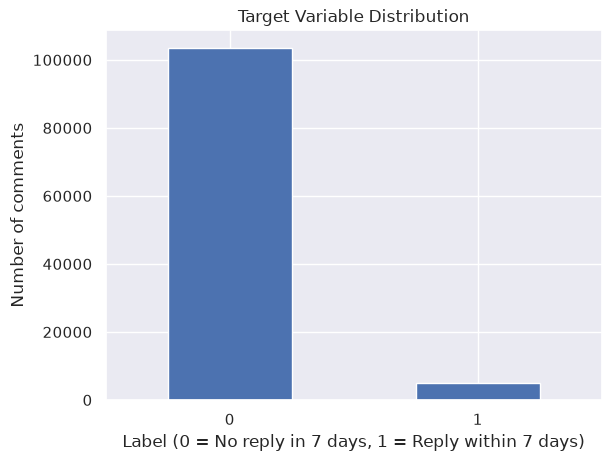

In [15]:
sns.set()
df['label'].value_counts().plot(kind='bar', rot=0)
plt.title('Target Variable Distribution')
plt.xlabel('Label (0 = No reply in 7 days, 1 = Reply within 7 days)')
plt.ylabel('Number of comments')
plt.show()

# Comment & Target Variable

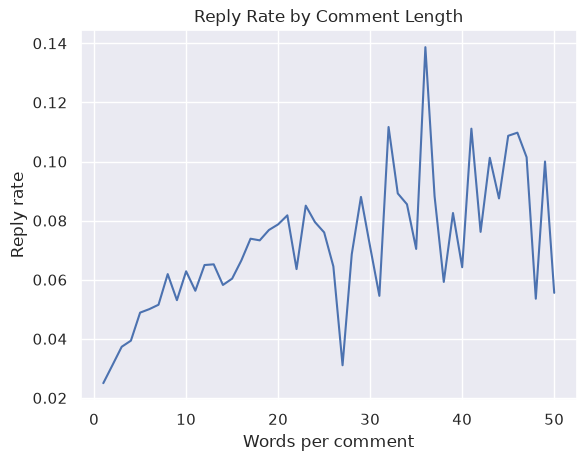

In [16]:
df['n_words'] = df['comment_text'].str.split().str.len()

df[df['n_words'] <= 50].groupby('n_words')['label'].mean().plot()
plt.title('Reply Rate by Comment Length')
plt.xlabel('Words per comment')
plt.ylabel('Reply rate')
plt.show()

# video_content & target variable 

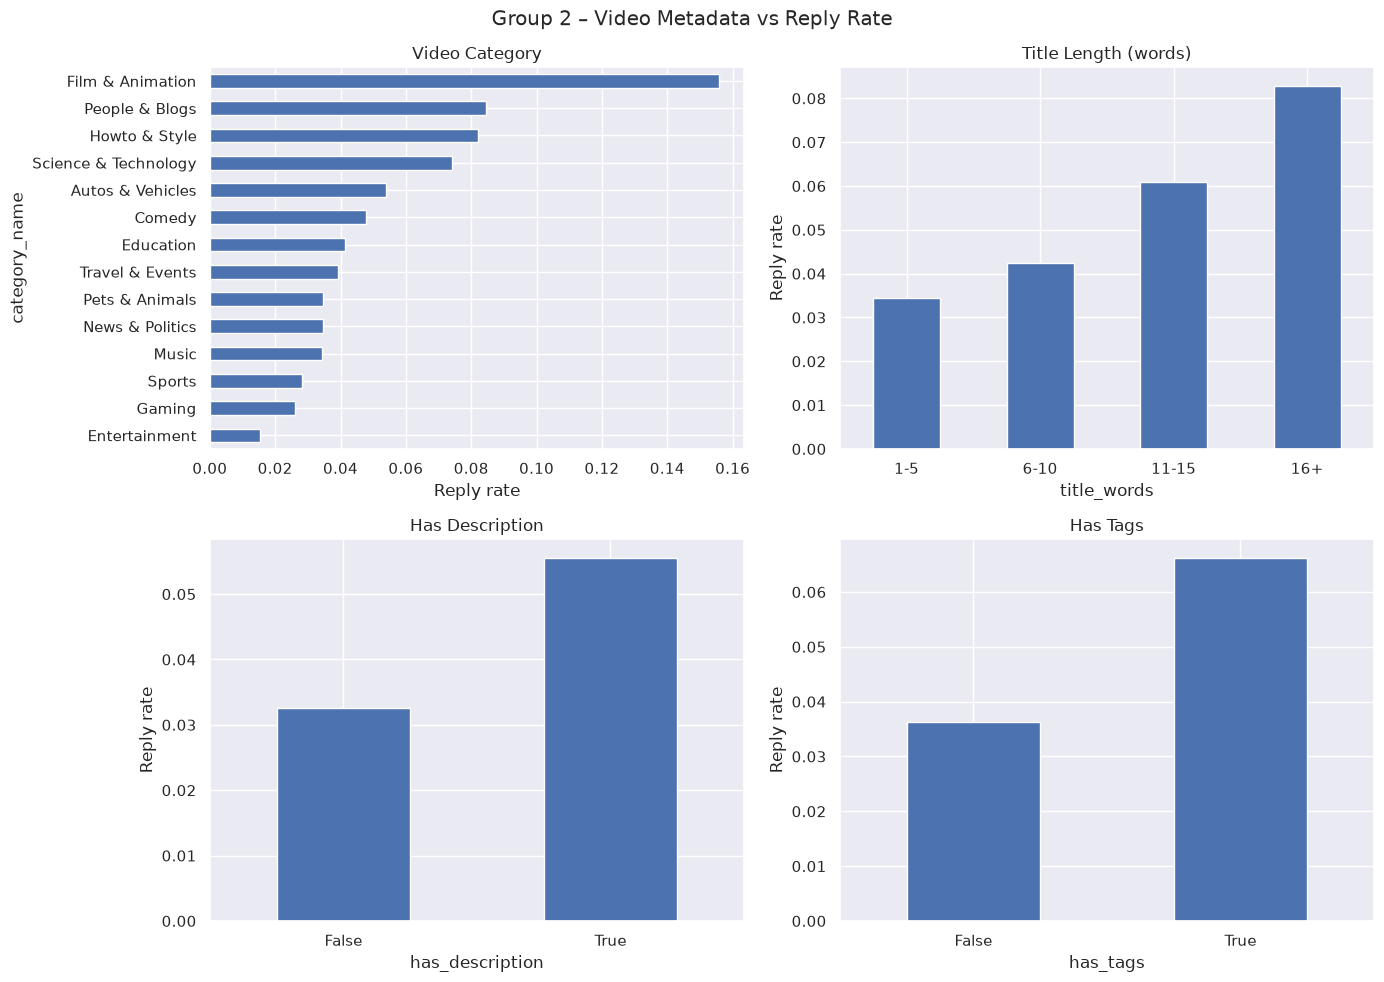

In [18]:
category_names = {1: "Film & Animation", 2: "Autos & Vehicles", 10: "Music",
                  15: "Pets & Animals", 17: "Sports", 19: "Travel & Events",
                  20: "Gaming", 22: "People & Blogs", 23: "Comedy",
                  24: "Entertainment", 25: "News & Politics", 26: "Howto & Style",
                  27: "Education", 28: "Science & Technology"}

df['category_name']   = df['video_category'].map(category_names)
df['title_words']     = pd.cut(df['video_title'].str.split().str.len(),
                               bins=[0, 5, 10, 15, 100], labels=['1-5', '6-10', '11-15', '16+'])
df['has_description'] = df['video_description'].str.strip() != ''
df['has_tags']        = df['video_tags'].str.len() > 0

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df.groupby('category_name')['label'].mean().sort_values().plot(kind='barh', ax=axes[0, 0])
axes[0, 0].set_title('Video Category')
axes[0, 0].set_xlabel('Reply rate')

df.groupby('title_words', observed=True)['label'].mean().plot(kind='bar', rot=0, ax=axes[0, 1])
axes[0, 1].set_title('Title Length (words)')
axes[0, 1].set_ylabel('Reply rate')

df.groupby('has_description')['label'].mean().plot(kind='bar', rot=0, ax=axes[1, 0])
axes[1, 0].set_title('Has Description')
axes[1, 0].set_ylabel('Reply rate')

df.groupby('has_tags')['label'].mean().plot(kind='bar', rot=0, ax=axes[1, 1])
axes[1, 1].set_title('Has Tags')
axes[1, 1].set_ylabel('Reply rate')

plt.suptitle('Group 2 – Video Metadata vs Reply Rate')
plt.tight_layout()
plt.show()

In [ ]:
# Model 3 temporal feature & target variable

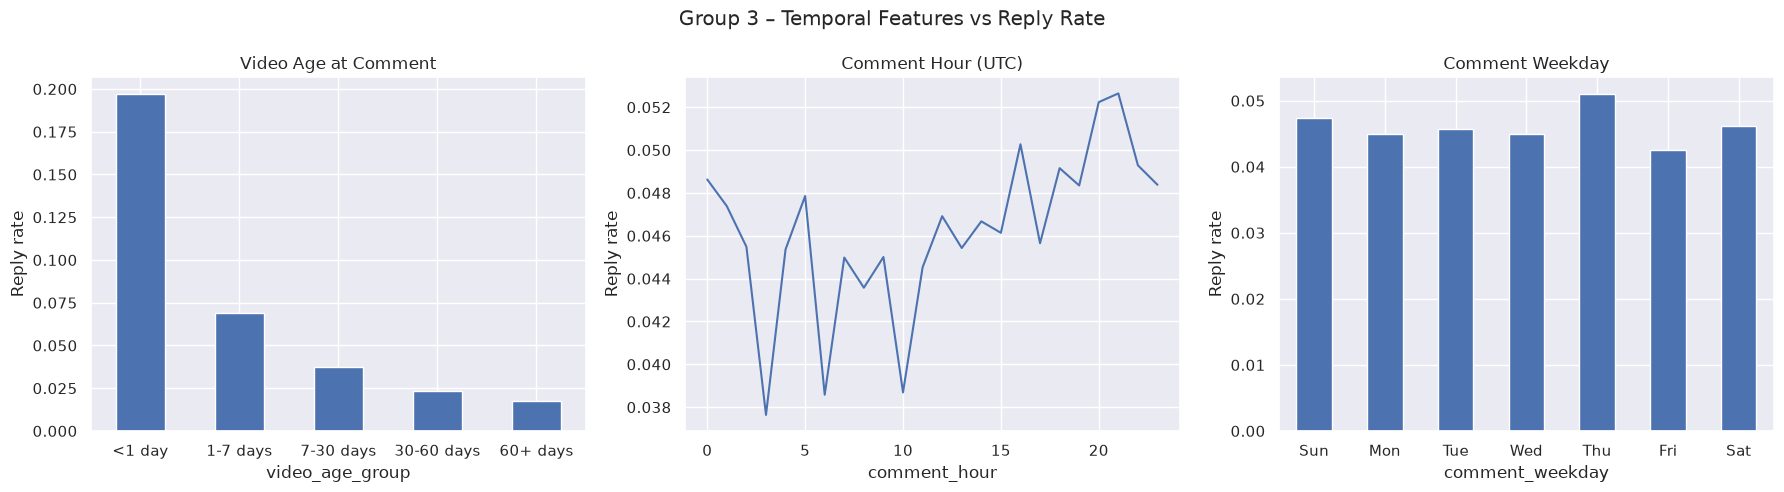

In [19]:
df['video_age_group'] = pd.cut(df['video_age_at_comment'] / 24,
                               bins=[0, 1, 7, 30, 60, 100],
                               labels=['<1 day', '1-7 days', '7-30 days', '30-60 days', '60+ days'],
                               include_lowest=True)

weekday_names = {1: 'Sun', 2: 'Mon', 3: 'Tue', 4: 'Wed', 5: 'Thu', 6: 'Fri', 7: 'Sat'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df.groupby('video_age_group', observed=True)['label'].mean().plot(kind='bar', rot=0, ax=axes[0])
axes[0].set_title('Video Age at Comment')
axes[0].set_ylabel('Reply rate')

df.groupby('comment_hour')['label'].mean().plot(ax=axes[1])
axes[1].set_title('Comment Hour (UTC)')
axes[1].set_ylabel('Reply rate')

df.groupby('comment_weekday')['label'].mean().rename(weekday_names).plot(kind='bar', rot=0, ax=axes[2])
axes[2].set_title('Comment Weekday')
axes[2].set_ylabel('Reply rate')

plt.suptitle('Group 3 – Temporal Features vs Reply Rate')
plt.tight_layout()
plt.show()

In [20]:
df['n_words'].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

count    108524.000000
mean          8.013499
std          15.287248
min           1.000000
50%           5.000000
75%           9.000000
90%          17.000000
95%          25.000000
99%          54.000000
max        1717.000000
Name: n_words, dtype: float64

In [21]:
video_text = df['video_title'] + ' ' + df['video_description'] + ' ' + df['video_tags'].str.join(' ')
video_text.str.split().str.len().describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

count    108524.000000
mean         72.614657
std         131.192338
min           2.000000
50%          22.000000
75%          81.000000
90%         177.000000
95%         302.000000
99%         800.000000
max         908.000000
dtype: float64

# Split Train - test- validation 
group-aware split by video_id was used to prevent data leakage, since video-level features are shared across comments of the same video

In [22]:
from sklearn.model_selection import GroupShuffleSplit

# 1) 70% train – 30% temp
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss.split(df, groups=df['video_id']))
train_df = df.iloc[train_idx]
temp_df  = df.iloc[temp_idx]

# 2) temp -> 50% validation – 50% test
gss = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss.split(temp_df, groups=temp_df['video_id']))
val_df  = temp_df.iloc[val_idx]
test_df = temp_df.iloc[test_idx]

for name, part in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    print(f"{name:<11} rows: {len(part):>6} | videos: {part['video_id'].nunique():>3} | positive: {part['label'].mean():.2%}")

Train       rows:  73929 | videos: 402 | positive: 4.30%
Validation  rows:  17076 | videos:  86 | positive: 6.45%
Test        rows:  17519 | videos:  87 | positive: 4.15%


In [ ]:
# Text Vectorization (Group 1: comment_text)

In [24]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

COMMENT_MAX_LEN = 30
VOCAB_SIZE = 20000

comment_vectorizer = TextVectorization(max_tokens=VOCAB_SIZE,
                                       output_sequence_length=COMMENT_MAX_LEN)
comment_vectorizer.adapt(train_df['comment_text'].values)

X_train_comment = comment_vectorizer(train_df['comment_text'].values)
X_val_comment   = comment_vectorizer(val_df['comment_text'].values)
X_test_comment  = comment_vectorizer(test_df['comment_text'].values)

print("Train shape:", X_train_comment.shape)
print("Example:", train_df['comment_text'].iloc[0])
print("Encoded:", X_train_comment[0].numpy())

I0000 00:00:1791475253.271265   15634 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791475254.067061   15634 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791475258.595152   15634 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


     88/Unknown 0s 2ms/step

E0000 00:00:1791475259.509305   15634 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



  73929/Unknown 212s 3ms/step
Train shape: (73929, 30)
Example: bang gati  ban  nya yang gede
Encoded: [  206     1  2231   367   288 13421     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0]


W0000 00:00:1791475471.818591   15634 cpu_allocator_impl.cc:174] Allocation of 17742960 exceeds 10% of free system memory.


# Text Vectorization (Group 2: video text)

In [25]:
VIDEO_MAX_LEN = 200

def build_video_text(d):
    return d['video_title'] + ' ' + d['video_description'] + ' ' + d['video_tags'].str.join(' ')

train_df = train_df.assign(video_text=build_video_text(train_df))
val_df   = val_df.assign(video_text=build_video_text(val_df))
test_df  = test_df.assign(video_text=build_video_text(test_df))

video_vectorizer = TextVectorization(max_tokens=VOCAB_SIZE,
                                     output_sequence_length=VIDEO_MAX_LEN)
video_vectorizer.adapt(train_df.drop_duplicates('video_id')['video_text'].values)

X_train_video = video_vectorizer(train_df['video_text'].values)
X_val_video   = video_vectorizer(val_df['video_text'].values)
X_test_video  = video_vectorizer(test_df['video_text'].values)

print("Train shape:", X_train_video.shape)

    402/Unknown 1s 3ms/step


W0000 00:00:1791476030.555151   15634 cpu_allocator_impl.cc:174] Allocation of 83668128 exceeds 10% of free system memory.
W0000 00:00:1791476030.555305   15634 cpu_allocator_impl.cc:174] Allocation of 125502192 exceeds 10% of free system memory.
W0000 00:00:1791476031.724023   15634 cpu_allocator_impl.cc:174] Allocation of 41834064 exceeds 10% of free system memory.
W0000 00:00:1791476031.938253   15634 cpu_allocator_impl.cc:174] Allocation of 20917032 exceeds 10% of free system memory.


Train shape: (73929, 200)


# One-Hot Encoding (Group 2: video_category)

In [27]:
from sklearn.preprocessing import OneHotEncoder

category_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
category_encoder.fit(train_df[['video_category']])

X_train_cat = category_encoder.transform(train_df[['video_category']])
X_val_cat   = category_encoder.transform(val_df[['video_category']])
X_test_cat  = category_encoder.transform(test_df[['video_category']])

print("Categories:", category_encoder.categories_[0])
print("Train shape:", X_train_cat.shape)

Categories: [ 1  2 10 15 17 19 20 22 23 24 25 26 27 28]
Train shape: (73929, 14)


# Feature Scaling (Group 3: temporal features)

In [28]:
from sklearn.preprocessing import StandardScaler

temporal_cols = ['video_age_at_comment', 'comment_hour', 'comment_weekday']

scaler = StandardScaler()
X_train_time = scaler.fit_transform(train_df[temporal_cols])
X_val_time   = scaler.transform(val_df[temporal_cols])
X_test_time  = scaler.transform(test_df[temporal_cols])

print("Train shape:", X_train_time.shape)
print("Train mean:", X_train_time.mean(axis=0).round(2))
print("Train std: ", X_train_time.std(axis=0).round(2))

Train shape: (73929, 3)
Train mean: [ 0. -0.  0.]
Train std:  [1. 1. 1.]


# Target Variable and Class Weights

In [30]:
import numpy as np

from sklearn.utils.class_weight import compute_class_weight

y_train = train_df['label'].values
y_val   = val_df['label'].values
y_test  = test_df['label'].values

weights = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}

print("Class weights:", class_weight)

Class weights: {0: np.float64(0.522488586088456), 1: np.float64(11.616750471401634)}
